Pojęcia:
- Korpus (corpus) - zbiór dokumentów;
- Tokenizacja to segmentacja dzieląca tekst na tokeny;
- Token - efektywna w danym zastosowaniu NLP jednostka informacji, zazwyczaj słowo lub litera;
- Słownik (vocabulary) - zbiór tokenów (dla danego korpusu);
- Reprezentacja (dokumnetu) BoW.

Korpus zawiera 3 dokumenty:

In [1]:
doc1 = 'I have learned that people will forget what you said, people will forget what you did, but people will never forget how you made them feel'
doc2 = 'Ask not what the Earth can do for you; ask what you can do for the Earth'
doc3 = 'Government of the people, by the people, and for the people, shall not perish from the earth'

Tokenizacja:

In [2]:
from nltk.tokenize import TreebankWordTokenizer

tokenizer = TreebankWordTokenizer()
tokens = tokenizer.tokenize(doc1.lower())

Reprezentacja Bag-of-Words:

In [3]:
from collections import Counter
BoW = Counter(tokens)
BoW

Counter({'people': 3,
         'will': 3,
         'forget': 3,
         'you': 3,
         'what': 2,
         ',': 2,
         'i': 1,
         'have': 1,
         'learned': 1,
         'that': 1,
         'said': 1,
         'did': 1,
         'but': 1,
         'never': 1,
         'how': 1,
         'made': 1,
         'them': 1,
         'feel': 1})

In [4]:
BoW.most_common(3)

[('people', 3), ('will', 3), ('forget', 3)]

Pozostałe fragmenty:

In [5]:
tokens = tokenizer.tokenize(doc2.lower())
Counter(tokens)

Counter({'ask': 2,
         'what': 2,
         'the': 2,
         'earth': 2,
         'can': 2,
         'do': 2,
         'for': 2,
         'you': 2,
         'not': 1,
         ';': 1})

In [6]:
tokens = tokenizer.tokenize(doc3.lower())
Counter(tokens)

Counter({'the': 4,
         'people': 3,
         ',': 3,
         'government': 1,
         'of': 1,
         'by': 1,
         'and': 1,
         'for': 1,
         'shall': 1,
         'not': 1,
         'perish': 1,
         'from': 1,
         'earth': 1})

# Wektorowa reprezentacja BoW
- BoW jest zbiorem tokenów (słów), dla każdego możemy przechowywać liczbę wystąpień każdego tokenu;
- W praktyce bardzej przydatna jest reprezentacja w postaci wektora BoW;
- Wektor BoW także reprezentuje wystąpienia tokenów lub liczbę wystąpień każdego tokenu, przy czym wystąpienie/liczba są na pozycji wektora odpowadiającej danemu tokenowi.

Tworzenie wektorów BoW przy użyciu `CountVectorizer` biblioteki `sckit-learn`

In [7]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer()
cv.fit([doc1, doc2, doc3])

,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"stop_words stop_words: {'english'}, list, default=NoneIf 'english', a built-in stop word list for English is used.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str or None, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp select tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentword n-grams or char n-grams to be extracted. All values of n suchsuch that min_n <= n <= max_n will be used. For example an``ngram_range`` of ``(1, 1)`` means only unigrams, ``(1, 2)`` meansunigrams and bigrams, and ``(2, 2)`` means only bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word n-gram or charactern-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21Since v0.21, if ``input`` is ``filename`` or ``file``, the data isfirst read from the file and then passed to the given callableanalyzer.",'word'


Wspólny słownik tokenów dla całego korpusu:

In [8]:
list(cv.vocabulary_.keys())

['have',
 'learned',
 'that',
 'people',
 'will',
 'forget',
 'what',
 'you',
 'said',
 'did',
 'but',
 'never',
 'how',
 'made',
 'them',
 'feel',
 'ask',
 'not',
 'the',
 'earth',
 'can',
 'do',
 'for',
 'government',
 'of',
 'by',
 'and',
 'shall',
 'perish',
 'from']

Przedstawienie w formie wektorów BoW za pomocą ramki danych:

In [26]:
import pandas as pd
pd.set_option('display.max_columns', 15)  # ograniczenie liczby wyświetlanych kolumn

BoW_vectors = cv.transform([doc1, doc2, doc3]).todense()
inv_vocabulary = {v: k for k, v in cv.vocabulary_.items()}
df = pd.DataFrame.from_dict(inv_vocabulary, orient='index', columns=['token']).sort_index()
df_vectors = pd.DataFrame(BoW_vectors.T, columns=['doc1', 'doc2', 'doc3'])
BoW_vectors = df.join(df_vectors).T  # <- .T oznacza transpozycję, odwracającą wiersze z kolumnami
BoW_vectors

# Stworzenie struktury danuych w taki sposób, że wiersze reprezentują dokumenty,
# a kolumny reprezentują tokeny (słowa), a wartości to liczba wystąpień danego tokena w danym dokumencie.

,0,1,2,3,4,5,6,...,23,24,25,26,27,28,29
token,and,ask,but,by,can,did,do,...,shall,that,the,them,what,will,you
doc1,0,0,1,0,0,1,0,...,0,1,0,1,2,3,3
doc2,0,2,0,0,2,0,2,...,0,0,2,0,2,0,2
doc3,1,0,0,1,0,0,0,...,1,0,4,0,0,0,0


In [10]:
BoW_vectors.T

,token,doc1,doc2,doc3
0,and,0,0,1
1,ask,0,2,0
2,but,1,0,0
3,by,0,0,1
4,can,0,2,0
5,did,1,0,0
6,do,0,2,0
7,earth,0,2,1
8,feel,1,0,0
9,for,0,2,1


# Wydźwięk - uczenie maszynowe z wykorzystaniem wektorów BoW

Pobranie danych (z ograniczeniem do 10.000 najczęściej występujących w recenzjach słów) - opis danych: [tutaj](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews)

Biblioteka tensorflow zazywaczaj wymaga wcześniejszej wersji środowiska pythona, często trzeba robic venva od nowa, można też pobrać whl ze: [strony](https://www.tensorflow.org/install/pip?hl=pl#windows-wsl2)

In [11]:
# !pip install tensorflow

Pobranie danych (z ograniczeniem 10.000 najczęściej występujących w recenzjach słów). Link do danych: [tutaj](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews)

In [12]:
from tensorflow.keras.datasets import imdb
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=10000) 

Konwersja do reprezentacji wektorowej BoW:

In [13]:
import numpy as np
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        for j in sequence:
            results[i, j] = 1.
    return results

X_train = vectorize_sequences(X_train)
X_test = vectorize_sequences(X_test)

Uczenie i testowanie modelu:

In [14]:
from sklearn.naive_bayes import MultinomialNB

clf = MultinomialNB()
clf.fit(X_train, y_train)
print(f'Dokładność = {clf.score(X_test, y_test):0.2}')

Dokładność = 0.84


# Wizualizacja wektorów BoW
- Wektory BoW reprezentują dokumenty w wielowymiarowej przestrzeni;
- Jeżeli ograniczymy się do maksymalnie 3 wymiarów, wektory można wizualizować na wykresie.

Bierzemy pod uwagę tylko 2 wymiary - dla słów `people` i `earth`:

In [15]:
i1 = cv.vocabulary_['people']
i2 = cv.vocabulary_['earth']
BoW_vectors.iloc[:, [i1, i2]]

,20,7
token,people,earth
doc1,3,0
doc2,0,2
doc3,3,1


Współrzędne wektorów dla tych 2 wymiarów:

In [16]:
V1 = BoW_vectors.iloc[1,[i1, i2]].values
V2 = BoW_vectors.iloc[2,[i1, i2]].values
V3 = BoW_vectors.iloc[3,[i1, i2]].values
print(f'V1 = {V1}, V2 = {V2}, V3 = {V3}')

V1 = [3 0], V2 = [0 2], V3 = [3 1]


Rysunek wektorów dla tych 2 wymiarów:

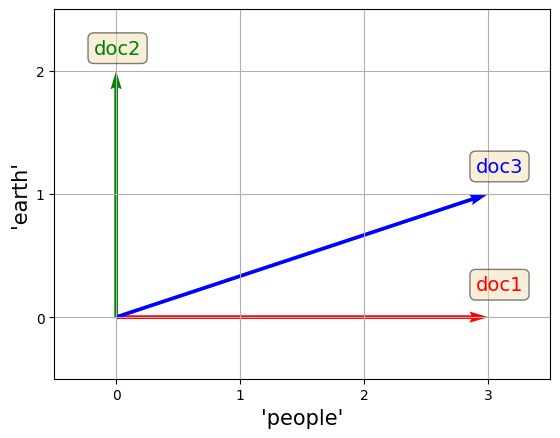

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

fig, ax = plt.subplots()

ax.quiver(0, 0, V1[0], V1[1], angles='xy', scale_units='xy', scale=1, color='r')
ax.quiver(0, 0, V2[0], V2[1], angles='xy', scale_units='xy', scale=1, color='g')
ax.quiver(0, 0, V3[0], V3[1], angles='xy', scale_units='xy', scale=1, color='b')

ax.set_xlim([-0.5, 3.5])
ax.set_ylim([-0.5, 2.5])

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.xlabel("'people'", fontsize=15)
plt.ylabel("'earth'", fontsize=15)

props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.85, 0.28, 'doc1', transform=ax.transAxes, fontsize=14,
        verticalalignment='top', bbox=props, color='r')
ax.text(0.08, 0.92, 'doc2', transform=ax.transAxes, fontsize=14,
        verticalalignment='top', bbox=props, color='g')
ax.text(0.85, 0.6, 'doc3', transform=ax.transAxes, fontsize=14,
        verticalalignment='top', bbox=props, color='b')

plt.grid()
          

Do porównania dwóch n-wymiarowych wektorów w i v 
można wykorzystać iloczyn skalarny:
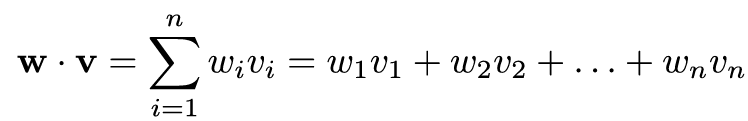

- Iloczyn skalarny będzie większy dla dłuższych wektorów, co jest niepożądane w naszym zastosowaniu
- Dlatego warto uwzględnić także długość wektora przy wyliczaniu podobieństwa

Korzystając ze wzoru na iloczyn skalarny:

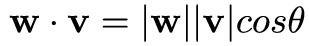

po przekształceniach uzyskamy:

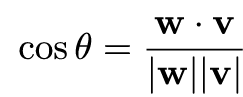


# Kosinusowa miara podobieństwa

Miara kosinusowa jest równa:
- 1 dla wektorów o tym samym kierunku i zwrocie
- -1 dla wektorów o tym samym kierunku i przeciwnym zwrocie
- 0 dla wektorów ortogonalnych

W przypadku wektorów BoW współrzędne są nieujemne, więc 
miara będzie przedziale od 0 do 1
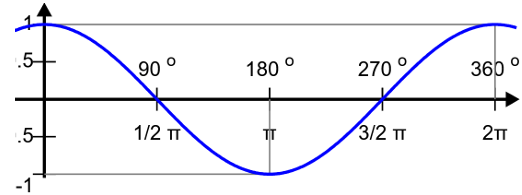

Podobieństwo kosiunusowe dla tych 2 wymiarów:

In [27]:
length_V1 = np.linalg.norm(V1)
length_V2 = np.linalg.norm(V2)
length_V3 = np.linalg.norm(V3)
print(f'podobieństwo kosinusowe(doc1,doc2) = {np.dot(V1, V2)/(length_V1*length_V2):0.3}')
print(f'podobieństwo kosinusowe(doc2,doc3) = {np.dot(V2, V3)/(length_V2*length_V3):0.3}')
print(f'podobieństwo kosinusowe(doc1,doc3) = {np.dot(V1, V3)/(length_V1*length_V3):0.3}')

podobieństwo kosinusowe(doc1,doc2) = 0.0
podobieństwo kosinusowe(doc2,doc3) = 0.316
podobieństwo kosinusowe(doc1,doc3) = 0.949


Podobieństwo kosiunusowe dla wszystkich wymiarów:

In [28]:
V1 = BoW_vectors.loc['doc1',:]
V2 = BoW_vectors.loc['doc2',:]
V3 = BoW_vectors.loc['doc3',:]
length_V1 = np.linalg.norm(V1)
length_V2 = np.linalg.norm(V2)
length_V3 = np.linalg.norm(V3)
print(f'podobieństwo kosinusowe(doc1,doc2) = {np.dot(V1, V2)/(length_V1*length_V2):0.3}')
print(f'podobieństwo kosinusowe(doc2,doc3) = {np.dot(V2, V3)/(length_V2*length_V3):0.3}')
print(f'podobieństwo kosinusowe(doc1,doc3) = {np.dot(V1, V3)/(length_V1*length_V3):0.3}')

podobieństwo kosinusowe(doc1,doc2) = 0.244
podobieństwo kosinusowe(doc2,doc3) = 0.383
podobieństwo kosinusowe(doc1,doc3) = 0.213


# Wektory TF

- 
Uogólnieniem liczby wystąpień tokena jest częstość 
termu (tokenu), oznaczana TF (term frequency):

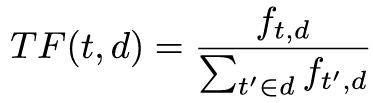

gdzie t oznacza term (token), d dokument, a ft,d 
częstość występowania termu (tokenu) w dokumencie



Inne warianty TF:
- binarny: TF wynosi 0 (brak t w d) lub 1 (jest)
- liczba wystąpień (jak w BoW)
- logarytmiczna: TF(t,d) = log(1 + ft,d) 

Obiekt [TfidfVectorizer](https://scikit-learn.org/1.5/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) umożliwia podanie TF dla 
`use_idf=False`


# Wektorowa reprezentacja TF-IDF


- Dodatkową informacją, którą można 
wykorzystać aby określić istotność danego 
słowa, jest częstość występowania tego słowa 
w różnych dokumentach korpusu
- Im rzadziej słowo występuje w korpusie, tym 
bardziej charakterystyczne jest dla 
dokumentów, w których wystąpiło

Aby nadać tej ważności wartość liczbową 
wprowadzono wskaźnik IDF (inversed document 
frequency):

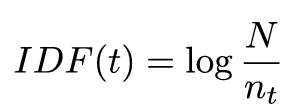

gdzie N jest liczbą dokumentów w korpusie, a nt 
liczba dokumentów, w których pojawia się t 



Korzystamy z `TfidfVectorizer`:

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
tf = TfidfVectorizer(use_idf=True, norm=None)
tf.fit([doc1,doc2,doc3])

,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'word'
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1


Często stosowany jest wariant wygładzony 
(smooth):

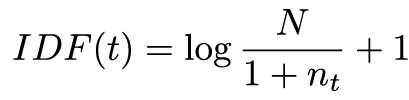

lub

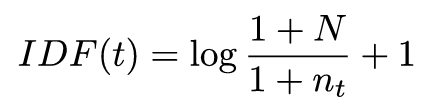

Przedstawienie w formie wektorów TF-IDF za pomocą ramki danych:

- TF-IDF polega na pomnożeniu częstości termu i odwróconej częstości dokumentu
- Obiekt [TfidfVectorizer](https://scikit-learn.org/1.5/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) wylicza TF-IDF dla 
`use_idf=True`


In [30]:
pd.options.display.float_format = '{:.3f}'.format # wyświetla 3 miejsca po przecinku

TF_vectors = tf.transform([doc1,doc2,doc3]).todense()
inv_vocabulary = {v: k for k, v in tf.vocabulary_.items()}
df = pd.DataFrame.from_dict(inv_vocabulary, orient='index', columns=['token']).sort_index()
df_vectors = pd.DataFrame(TF_vectors.T, columns=['doc1', 'doc2', 'doc3'])
TF_vectors = df.join(df_vectors).T
TF_vectors

,0,1,2,3,4,5,6,...,23,24,25,26,27,28,29
token,and,ask,but,by,can,did,do,...,shall,that,the,them,what,will,you
doc1,0.000,0.000,1.693,0.000,0.000,1.693,0.000,...,0.000,1.693,0.000,1.693,2.575,5.079,3.863
doc2,0.000,3.386,0.000,0.000,3.386,0.000,3.386,...,0.000,0.000,2.575,0.000,2.575,0.000,2.575
doc3,1.693,0.000,0.000,1.693,0.000,0.000,0.000,...,1.693,0.000,5.151,0.000,0.000,0.000,0.000


TF-IDF jest stosowany w wyszukiwaniu 
informacji, w szczególności w wyszukiwarkach 
internetowych, systemach antyplagiatowych, 
itp.

# Wykorzystanie reprezentacji BoW w klasyfikacji

In [31]:
from sklearn.datasets import fetch_20newsgroups

X_train, y_train = fetch_20newsgroups(subset='train', 
                                      return_X_y=True, 
                                      remove=('headers', 'footers', 'quotes'))
X_test, y_test = fetch_20newsgroups(subset='test', 
                                    return_X_y=True, 
                                    remove=('headers', 'footers', 'quotes'))

Utworzenie wektorów BoW:

In [32]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer()
X_train = cv.fit_transform(X_train)
X_test = cv.transform(X_test)

Wektory BoW (podobnie jak TF-IDF) mają dużą liczbę wymiarów:

In [33]:
# pojedynczy wektor dla 20newsgroups ma ponad 100k pozycji
X_train[0,:].shape

(1, 101631)

Wektory BoW (podobnie jak TF-IDF) są rzadkie:

In [34]:
(X_train[0,:] > 0).sum() # liczba niezerowych pozycji

np.int64(64)

Klasyfikacja za pomocą naiwnego klasyfikatora Bayesa:

In [35]:
from sklearn.naive_bayes import MultinomialNB

clf = MultinomialNB()
clf.fit(X_train, y_train)
print(f'Dokładność = {clf.score(X_test, y_test):0.2}')

Dokładność = 0.54


Dla porównania - wyliczenie dokładności klasyfikatora losującego z rozkładem prawdopodobieństwa o rozkładzie klas danych uczących:

In [36]:
import numpy as np

_, counts = np.unique(y_train, return_counts=True)
p = counts/len(y_train) # prawdopodobieństwa z rozkładu klas w zbiorze uczącycm
_, counts_pred = np.unique(y_test, return_counts=True)
p_pred = counts_pred/(len(y_test)) # prawdopodobieństwa klas w zbiorze testowym

print(f'Dokładność = {np.dot(p, p_pred):0.2}')

Dokładność = 0.051


# Wykorzystanie reprezentacji TF-IDF w klasyfikacji

In [38]:
from sklearn.datasets import fetch_20newsgroups

X_train, y_train = fetch_20newsgroups(subset='train', 
                                                 return_X_y=True, 
                                                 remove=('headers', 'footers', 'quotes'))
X_test, y_test = fetch_20newsgroups(subset='test', 
                                               return_X_y=True, 
                                               remove=('headers', 'footers', 'quotes'))

Utworzenie wektorów TFIDF:

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

tv = TfidfVectorizer(use_idf=True, norm=None)
X_train = tv.fit_transform(X_train)
X_test = tv.transform(X_test)

Klasyfikacja za pomocą naiwnego klasyfikatora Bayesa:

In [40]:
from sklearn.naive_bayes import MultinomialNB

clf = MultinomialNB()
clf.fit(X_train, y_train)
print(f'Dokładność = {clf.score(X_test, y_test):0.2}')

Dokładność = 0.66


Wektory TF-IDF, podobnie jak wektory BoW, są 
wektorami rzadkimi (składającymi się głównie z 
wartości zerowych), o stosunkowo dużej liczbie 
pozycji

In [41]:
# pojedynczy wektor dla 20newsgroups ma ponad 100k pozycji
X_train[0,:].shape

(1, 101631)

In [42]:
(X_train[0,:] > 0).sum() # liczba niezerowych pozycji

np.int64(64)